# TP 10 — Réseau de neurones (ANN)
**Deep Learning · Couche cachée · Rétropropagation · Epochs et batchs**

Ce TP reprend l’exemple de la présentation (diapos 71 à 77) :

| Partie de l’exemple | Diapo | Question |
|---|---|---|
| Une plante pousse bien entre deux températures : un seul neurone ne suffit pas | 74 | Q1 |
| Réseau 1 → 2 → 1 : calcul vers l’avant (forward) de l’epoch 1 | 72, 74 | Q2 |
| Rétropropagation et mise à jour de l’epoch 1 | 75 | Q3 |
| Entraînement complet et rôle de chaque neurone caché | 76 | Q4, Q5 |
| Epochs, batchs et itérations (`batch_size = 3`) | 73 | Q6 |

**Le problème.** Un agriculteur a noté, pour 6 serres, la température moyenne $T$ et si la plante a bien poussé ($y = 1$) ou non ($y = 0$) :

| $T$ (°C) | 10 | 15 | 20 | 25 | 30 | 35 |
|---|---|---|---|---|---|---|
| $y$ | 0 | 0 | 1 | 1 | 0 | 0 |

La plante aime la chaleur **modérée** : trop froid ou trop chaud, elle pousse mal. On travaille avec $x = T/10$ (donc $x = 1 ; 1{,}5 ; \dots ; 3{,}5$) pour garder des nombres simples.

**Objectifs** : programmer **en Python pur** le réseau, la perte, la rétropropagation et l’entraînement ; refaire les mêmes calculs avec **Keras** (et scikit-learn pour le neurone seul), avec les mêmes poids de départ ; puis **comparer** les deux implémentations pour valider le code.

## Rappel de cours (diapos 71 – 73)

**Un neurone** calcule $z = w\,x + b$ puis applique une activation : $\text{ReLU}(z) = \max(0 ; z)$ ou $\sigma(z) = \dfrac{1}{1 + e^{-z}}$.

**Notre réseau 1 → 2 → 1** (une entrée, deux neurones cachés ReLU, une sortie sigmoïde) :
$$h_1 = \max(0 ;\ w_1 x + b_1) \qquad h_2 = \max(0 ;\ w_2 x + b_2) \qquad p = \sigma(v_1 h_1 + v_2 h_2 + c)$$
$p$ est la probabilité que la plante pousse bien ; on prédit 1 si $p \ge 0{,}5$.

**Perte (log-loss)** sur $N$ exemples : $L = -\dfrac{1}{N}\sum \big[\,y\ln p + (1-y)\ln(1-p)\,\big]$.

**Rétropropagation** (dérivation en chaîne, de la sortie vers l’entrée), pour un exemple :
$$\delta = p - y \qquad \nabla v_1 = \delta\,h_1 \quad \nabla v_2 = \delta\,h_2 \quad \nabla c = \delta$$
$$\delta_1 = \delta\,v_1\,[z_1 > 0] \qquad \nabla w_1 = \delta_1\,x \quad \nabla b_1 = \delta_1 \qquad (\text{même chose pour } \delta_2,\ w_2,\ b_2)$$
$[z_1 > 0]$ vaut 1 si le neurone 1 est allumé, 0 sinon : **un neurone ReLU éteint ne reçoit aucun gradient**.

**Mise à jour** : poids $:=$ poids $- \eta \times$ gradient, avec la **moyenne** des gradients du batch.

**Vocabulaire** : une **itération** = un batch → forward → perte → backprop → mise à jour ; une **epoch** = toutes les données vues une fois ; itérations par epoch $= \lceil N/B \rceil$. Les poids ne repartent **jamais** de zéro.

In [ ]:
import math

T = [10, 15, 20, 25, 30, 35]           # températures (°C)
X = [t / 10 for t in T]                # normalization entrée du réseau : x = T / 10
Y = [0, 0, 1, 1, 0, 0]                 # 1 = la plante pousse bien
donnees = list(zip(X, Y))

sigmoide = lambda z: 1 / (1 + math.exp(-z))

---
# Partie A — Implémentation from scratch (Python pur)

### Question 1 — Pourquoi un seul neurone ne suffit-il pas ? (diapo 74)
**Réponse.** Un seul neurone sigmoïde (= régression logistique) calcule $p = \sigma(w x + b)$. Cette fonction est **monotone** : si $w > 0$, $p$ augmente avec la température ; si $w < 0$, elle diminue. Elle ne sait donc tracer qu’**une seule frontière** $x = -b/w$ : « chaud = oui » ou « froid = oui ». Or ici les « oui » sont **au milieu** (20 et 25 °C).

On le vérifie de deux façons :
1. on teste **toutes les frontières possibles** dans les deux sens : au mieux 4 serres sur 6 sont bien classées ;
2. on entraîne le neurone seul par descente de gradient : il ne trouve rien de mieux que de répondre « non » partout ($p \approx 2/6 = 0{,}33$ pour toutes les serres, 4/6 bien classées).

In [ ]:
# 1) Toutes les frontières possibles : seuil entre deux températures, dans les deux sens avant entrainement
meilleur = 0
for seuil in [0.75, 1.25, 1.75, 2.25, 2.75, 3.25, 3.75]:
    for sens in ["chaud = oui", "froid = oui"]:
        pred = [int(x > seuil) if sens == "chaud = oui" else int(x < seuil) for x in X]
        bons = sum(p == y for p, y in zip(pred, Y))
        meilleur = max(meilleur, bons)
        if bons >= 4:
            print(f"frontière T = {seuil*10:.1f} °C, {sens:<12} → {bons}/6 bien classées")
print("Meilleur score possible avec UNE frontière :", meilleur, "/ 6")

frontière T = 7.5 °C, froid = oui  → 4/6 bien classées
frontière T = 17.5 °C, chaud = oui  → 4/6 bien classées
frontière T = 27.5 °C, froid = oui  → 4/6 bien classées
frontière T = 37.5 °C, chaud = oui  → 4/6 bien classées
Meilleur score possible avec UNE frontière : 4 / 6


In [ ]:
# 2) Le neurone seul entraîné par descente de gradient (comme au TP2)
def entrainer_neurone_seul(eta=0.5, iterations=5000):
    w, b = 0.0, 0.0
    for _ in range(iterations):
        gw = gb = 0.0
        for x, y in donnees:
            p = sigmoide(w * x + b)
            gw += (p - y) * x
            gb += (p - y)
        w -= eta * gw / len(donnees)
        b -= eta * gb / len(donnees)
    return w, b

w_seul, b_seul = entrainer_neurone_seul()
p_seul = [sigmoide(w_seul * x + b_seul) for x in X]
acc_seul = sum(int(p >= 0.5) == y for p, y in zip(p_seul, Y))
print(f"w = {w_seul:.4f}   b = {b_seul:.4f}")
print("p pour chaque serre :", [round(p, 2) for p in p_seul])
print(f"Bien classées : {acc_seul}/6  → le neurone répond « non » partout")

w = -0.0000   b = -0.6931
p pour chaque serre : [0.33, 0.33, 0.33, 0.33, 0.33, 0.33]
Bien classées : 4/6  → le neurone répond « non » partout


**Conclusion.** $w \approx 0$ et $b \approx \ln(2/4) = -0{,}69$ : le neurone a « abandonné » la température et prédit la proportion moyenne de « oui ». Il faut **deux frontières** (vers 15–20 °C et vers 25–30 °C), donc **au moins deux neurones cachés**.

### Question 2 — Programmer le réseau 1 → 2 → 1 et faire le forward de l’epoch 1 (diapos 72 et 74)
**Réponse:** Les 7 paramètres sont rangés dans un dictionnaire. Poids de départ de la diapo 74 :

| $w_1$ | $b_1$ | $w_2$ | $b_2$ | $v_1$ | $v_2$ | $c$ |
|---|---|---|---|---|---|---|
| 2 | −3,5 | 2 | −6,5 | 1 | −3 | −1 |

Le neurone 1 s’allume quand $2x - 3{,}5 > 0$, soit $T > 17{,}5$ °C (« il fait assez chaud ») ; le neurone 2 quand $2x - 6{,}5 > 0$, soit $T > 32{,}5$ °C (« il fait trop chaud »). Son poids de sortie $v_2 = -3$ est **négatif** : il fait baisser $p$.

In [ ]:
NOMS = ["w1", "b1", "w2", "b2", "v1", "v2", "c"] #v1,v2 poids de couche sortie et c son biais
depart = {"w1": 2.0, "b1": -3.5, "w2": 2.0, "b2": -6.5, "v1": 1.0, "v2": -3.0, "c": -1.0}

def forward(P, x):
    z1 = P["w1"] * x + P["b1"];  h1 = max(0.0, z1)      # neurone caché 1 (ReLU)
    z2 = P["w2"] * x + P["b2"];  h2 = max(0.0, z2)      # neurone caché 2 (ReLU)
    z = P["v1"] * h1 + P["v2"] * h2 + P["c"]            # neurone de sortie
    return z1, h1, z2, h2, z, sigmoide(z)

def perte_moyenne(P, exemples=None):
    exemples = exemples or donnees
    total = 0.0
    for x, y in exemples:
        p = forward(P, x)[-1] #dernière valeur de P dans couche de sortie
        total += -(y * math.log(p) + (1 - y) * math.log(1 - p)) #loss function
    return total / len(exemples)    #perte moyenne=somme d'erreurs / nb exemples

print(" T    x  y |   z1    h1 |   z2    h2 |    z      p   prédit")
for x, y in donnees:
    z1, h1, z2, h2, z, p = forward(depart, x)
    print(f"{x*10:>2.0f}  {x:>3}  {y} | {z1:>5.2f} {h1:>5.2f} | {z2:>5.2f} {h2:>5.2f} | {z:>5.2f}  {p:.3f}   {int(p >= 0.5)}")
L0 = perte_moyenne(depart)
acc0 = sum(int(forward(depart, x)[-1] >= 0.5) == y for x, y in donnees)
print(f"Perte de départ = {L0:.3f} ; bien classées = {acc0}/6")

 T    x  y |   z1    h1 |   z2    h2 |    z      p   prédit
10  1.0  0 | -1.50  0.00 | -4.50  0.00 | -1.00  0.269   0
15  1.5  0 | -0.50  0.00 | -3.50  0.00 | -1.00  0.269   0
20  2.0  1 |  0.50  0.50 | -2.50  0.00 | -0.50  0.378   0
25  2.5  1 |  1.50  1.50 | -1.50  0.00 |  0.50  0.622   1
30  3.0  0 |  2.50  2.50 | -0.50  0.00 |  1.50  0.818   1
35  3.5  0 |  3.50  3.50 |  0.50  0.50 |  1.00  0.731   1
Perte de départ = 0.848 ; bien classées = 3/6


**Lecture.** Exemple détaillé pour $T = 20$ °C ($x = 2$) : $z_1 = 2\times2 - 3{,}5 = 0{,}5$ donc $h_1 = 0{,}5$ ; $z_2 = 2\times2 - 6{,}5 = -2{,}5$ donc $h_2 = 0$ (éteint) ; $z = 1\times0{,}5 - 3\times0 - 1 = -0{,}5$ et $p = \sigma(-0{,}5) = 0{,}38$. Le réseau se trompe (la plante pousse bien à 20 °C) : il doit apprendre. Au départ, seules 3 serres sur 6 sont bien classées et la perte vaut 0,848.

### Question 3 — Rétropropagation et mise à jour de l’epoch 1
**Réponse.** On utilise les 6 serres en un seul batch (`batch_size = 6`, une itération par epoch) et $\eta = 0{,}2$. Pour chaque serre on calcule $\delta = p - y$, puis l’erreur qui arrive à chaque neurone caché : $\delta_1 = \delta\,v_1$ si le neurone 1 est allumé, sinon 0 (idem $\delta_2 = \delta\,v_2$). On fait la moyenne des gradients sur les 6 serres, puis on met à jour.

In [ ]:
def gradients(P, exemples, detail=False): #P : paramètres et non pas probabilité
    g = {n: 0.0 for n in NOMS} #initialisation du dictionnaire des gradients
    for x, y in exemples:
        z1, h1, z2, h2, z, p = forward(P, x)
        delta = p - y                                       # erreur en sortie
        d1 = delta * P["v1"] * (1.0 if z1 > 0 else 0.0)     # erreur qui arrive au neurone 1
        d2 = delta * P["v2"] * (1.0 if z2 > 0 else 0.0)     # erreur qui arrive au neurone 2
        if detail:
            print(f"T = {x*10:>2.0f} : δ = {delta:>6.3f}   δ1 = {d1:>6.3f}   δ2 = {d2:>6.3f}")
        g["v1"] += delta * h1;  g["v2"] += delta * h2;  g["c"] += delta
        g["w1"] += d1 * x;      g["b1"] += d1
        g["w2"] += d2 * x;      g["b2"] += d2
    return {n: g[n] / len(exemples) for n in NOMS}

def mise_a_jour(P, g, eta):
    return {n: P[n] - eta * g[n] for n in NOMS}

ETA = 0.2
g1 = gradients(depart, donnees, detail=True)
P1 = mise_a_jour(depart, g1, ETA)
print()
print(f"{'':<4}{'départ':>9}{'gradient':>10}{'après epoch 1':>15}")
for n in NOMS:
    print(f"{n:<4}{depart[n]:>9.3f}{g1[n]:>10.3f}{P1[n]:>15.3f}")
acc1 = sum(int(forward(P1, x)[-1] >= 0.5) == y for x, y in donnees)
print(f"Perte : {L0:.3f} → {perte_moyenne(P1):.3f} ; bien classées : {acc0}/6 → {acc1}/6")

T = 10 : δ =  0.269   δ1 =  0.000   δ2 = -0.000
T = 15 : δ =  0.269   δ1 =  0.000   δ2 = -0.000
T = 20 : δ = -0.622   δ1 = -0.622   δ2 =  0.000
T = 25 : δ = -0.378   δ1 = -0.378   δ2 =  0.000
T = 30 : δ =  0.818   δ1 =  0.818   δ2 = -0.000
T = 35 : δ =  0.731   δ1 =  0.731   δ2 = -2.193

       départ  gradient  après epoch 1
w1      2.000     0.470          1.906
b1     -3.500     0.091         -3.518
w2      2.000    -1.279          2.256
b2     -6.500    -0.366         -6.427
v1      1.000     0.621          0.876
v2     -3.000     0.061         -3.012
c      -1.000     0.181         -1.036
Perte : 0.848 → 0.520 ; bien classées : 3/6 → 5/6


**Lecture.**
- À 10 et 15 °C les deux neurones cachés sont éteints : ces serres ne corrigent **que** le biais de sortie $c$ (sont étaints suite à Relu=0 h1=h2=0)
- Le neurone 2 n’est allumé qu’à 35 °C : c’est la **seule** serre qui corrige $w_2$ et $b_2$. Comme $\delta_2 = 0{,}731 \times (-3) = -2{,}19$ est négatif, la mise à jour **augmente** $w_2$ (2 → 2,256) : le neurone 2 s’allumera plus tôt, à $6{,}427/2{,}256 \times 10 = 28{,}5$ °C.
- Le gradient de $v_1$ est positif (le neurone 1 « pousse » trop les serres chaudes à 30 et 35 °C) : $v_1$ baisse de 1 à 0,876.

Après une seule epoch, la perte passe de 0,848 à 0,520.

### Question 4 — Entraîner le réseau pendant 1 000 epochs (diapo 76)
**Réponse.** On répète la question 3 : chaque epoch part des poids laissés par la précédente.

In [ ]:
def entrainer(P, epochs, eta=ETA, batch_size=6, suivi=()):
    P = dict(P)
    historique = {0: (dict(P), perte_moyenne(P))}
    for epoch in range(1, epochs + 1):
        for debut in range(0, len(donnees), batch_size):        # les batchs, dans l'ordre
            P = mise_a_jour(P, gradients(P, donnees[debut:debut + batch_size]), eta)
        historique[epoch] = (dict(P), perte_moyenne(P))
    return P, historique

P_final, hist = entrainer(depart, 1000)
print("epoch  perte   bien classées   p pour 10 … 35 °C")
for e in [0, 1, 10, 50, 100, 300, 500, 1000]:
    Pe, Le = hist[e]
    ps = [forward(Pe, x)[-1] for x in X]
    bons = sum(int(p >= 0.5) == y for p, y in zip(ps, Y))
    print(f"{e:>5}  {Le:.3f}       {bons}/6        {[round(p, 2) for p in ps]}")
print()
print("Poids après 1 000 epochs :", {n: round(v, 2) for n, v in P_final.items()})

epoch  perte   bien classées   p pour 10 … 35 °C
    0  0.848       3/6        [0.27, 0.27, 0.38, 0.62, 0.82, 0.73]
    1  0.520       5/6        [0.26, 0.26, 0.31, 0.51, 0.47, 0.06]
   10  0.282       6/6        [0.27, 0.29, 0.57, 0.79, 0.19, 0.02]
   50  0.233       6/6        [0.22, 0.33, 0.72, 0.8, 0.16, 0.01]
  100  0.193       6/6        [0.16, 0.29, 0.76, 0.82, 0.15, 0.01]
  300  0.107       6/6        [0.07, 0.18, 0.86, 0.89, 0.09, 0.0]
  500  0.068       6/6        [0.05, 0.12, 0.91, 0.93, 0.06, 0.0]
 1000  0.032       6/6        [0.02, 0.05, 0.96, 0.96, 0.03, 0.0]

Poids après 1 000 epochs : {'w1': 3.13, 'b1': -4.47, 'w2': 3.7, 'b2': -8.43, 'v1': 3.81, 'v2': -6.88, 'c': -3.71}


**Lecture.** Dès l’epoch 10 les 6 serres sont bien classées ; ensuite le réseau continue à gagner en **confiance** (la perte passe de 0,28 à 0,03). La perte baisse à chaque epoch : avec $\eta = 0{,}2$ et tout le jeu dans un seul batch, chaque pas va dans la bonne direction.

### Question 5 — Qu’a appris chaque neurone caché ? (diapo 76)
**Réponse.** Chaque neurone ReLU s’allume à partir d’une température seuil $T = -10\,b/w$. Le neurone de sortie combine les deux : $v_1 > 0$ (le neurone 1 vote « oui »), $v_2 < 0$ (le neurone 2 vote « non »), et le neurone 2 a un poids plus fort. Résultat : $p$ monte puis redescend, ce qu’un neurone seul ne sait pas faire.

In [ ]:
seuil1 = -P_final["b1"] / P_final["w1"] * 10
seuil2 = -P_final["b2"] / P_final["w2"] * 10
print(f"Neurone 1 « il fait assez chaud » : s'allume dès T = {seuil1:.1f} °C ; poids de sortie v1 = {P_final['v1']:+.2f}")
print(f"Neurone 2 « il fait trop chaud »  : s'allume dès T = {seuil2:.1f} °C ; poids de sortie v2 = {P_final['v2']:+.2f}")

# Zone où le réseau répond « oui » (p ≥ 0,5), cherchée au dixième de degré
zone = [t / 10 for t in range(50, 451) if forward(P_final, t / 100)[-1] >= 0.5]
print(f"Zone favorable apprise : de {zone[0]:.1f} °C à {zone[-1]:.1f} °C")

for t in [22, 33]:
    p = forward(P_final, t / 10)[-1]
    print(f"Nouvelle serre à {t} °C : p = {p:.2f} → {'pousse bien' if p >= 0.5 else 'pousse mal'}")

Neurone 1 « il fait assez chaud » : s'allume dès T = 14.3 °C ; poids de sortie v1 = +3.81
Neurone 2 « il fait trop chaud »  : s'allume dès T = 22.7 °C ; poids de sortie v2 = -6.88
Zone favorable apprise : de 17.5 °C à 27.4 °C
Nouvelle serre à 22 °C : p = 1.00 → pousse bien
Nouvelle serre à 33 °C : p = 0.00 → pousse mal


**Lecture.** Le neurone 1 s’allume vers 14 °C et fait monter $p$ ; le neurone 2 s’allume vers 23 °C et, avec un poids de sortie presque deux fois plus fort en négatif, finit par faire redescendre $p$. Le réseau a appris **deux frontières** : la plante pousse bien entre environ 17 et 27 °C.

### Question 6 — Epochs, batchs et itérations : `batch_size = 3`
**Réponse.** Avec $B = 3$, chaque epoch fait $\lceil 6/3 \rceil = 2$ itérations : batch 1 = {10, 15, 20 °C}, batch 2 = {25, 30, 35 °C}. La deuxième itération **part des poids laissés par la première** : on ne repart jamais de zéro.

In [ ]:
P = dict(depart)
iteration = 0
batchs = [donnees[0:3], donnees[3:6]]
for epoch in [1, 2]:
    for k, batch in enumerate(batchs, start=1):
        iteration += 1
        g = gradients(P, batch)
        P = mise_a_jour(P, g, ETA)
        bouges = [n for n in NOMS if abs(g[n]) > 1e-12]
        print(f"epoch {epoch} · itération {iteration} · batch {[int(x*10) for x, _ in batch]} °C")
        print(f"   paramètres corrigés : {bouges}")
        print(f"   poids → {{{', '.join(f'{n}: {P[n]:.2f}' for n in NOMS)}}}")
    print(f"   fin de l'epoch {epoch} : perte sur les 6 serres = {perte_moyenne(P):.3f}")

P_mini, hist_mini = entrainer(depart, 300, batch_size=3)
p_mini = [forward(P_mini, x)[-1] for x in X]
print()
print(f"Après 300 epochs = 600 itérations : perte = {hist_mini[300][1]:.3f} ; p = {[round(p, 2) for p in p_mini]}")

epoch 1 · itération 1 · batch [10, 15, 20] °C
   paramètres corrigés : ['w1', 'b1', 'v1', 'c']
   poids → {w1: 2.08, b1: -3.46, w2: 2.00, b2: -6.50, v1: 1.02, v2: -3.00, c: -0.99}
epoch 1 · itération 2 · batch [25, 30, 35] °C
   paramètres corrigés : ['w1', 'b1', 'w2', 'b2', 'v1', 'v2', 'c']
   poids → {w1: 1.77, b1: -3.55, w2: 2.56, b2: -6.34, v1: 0.69, v2: -3.03, c: -1.08}
   fin de l'epoch 1 : perte sur les 6 serres = 0.513
epoch 2 · itération 3 · batch [10, 15, 20] °C
   paramètres corrigés : ['c']
   poids → {w1: 1.77, b1: -3.55, w2: 2.56, b2: -6.34, v1: 0.69, v2: -3.03, c: -1.07}
epoch 2 · itération 4 · batch [25, 30, 35] °C
   paramètres corrigés : ['w1', 'b1', 'w2', 'b2', 'v1', 'v2', 'c']
   poids → {w1: 1.84, b1: -3.52, w2: 2.24, b2: -6.47, v1: 0.73, v2: -3.03, c: -1.03}
   fin de l'epoch 2 : perte sur les 6 serres = 0.544

Après 300 epochs = 600 itérations : perte = 0.093 ; p = [0.06, 0.2, 0.84, 0.94, 0.05, 0.0]


**Lecture.**
- Itération 1 : dans le batch {10, 15, 20 °C} le neurone 2 est éteint partout, donc $w_2$, $b_2$ et $v_2$ **ne bougent pas**.
- Itération 3 : après l’itération 2, $z_1(20\text{ °C}) = 1{,}77\times2 - 3{,}55 < 0$ : le neurone 1 est éteint pour tout le batch, seul $c$ est corrigé.
- La perte peut **remonter** d’une epoch à l’autre (0,513 → 0,544) : chaque mise à jour ne voit que la moitié des serres. Avec plus d’epochs, elle finit par baisser (0,093 après 600 itérations, 6/6 bien classées).

---
# Partie B — Les mêmes calculs avec une bibliothèque

### Question 7 — Le neurone seul avec scikit-learn
**Réponse.** `LogisticRegression` est exactement un neurone sigmoïde. On désactive la régularisation (`C` très grand) pour avoir le même problème qu’en Python pur.

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression

Xa = np.array(X).reshape(-1, 1)  #tableau de données
Ya = np.array(Y)
logit = LogisticRegression(C=1e6).fit(Xa, Ya)
p_sk = logit.predict_proba(Xa)[:, 1]
print(f"w = {logit.coef_[0, 0]:.4f}   b = {logit.intercept_[0]:.4f}")
print("p pour chaque serre :", p_sk.round(2))
print("Bien classées :", int(logit.score(Xa, Ya) * 6), "/ 6")

w = 0.0000   b = -0.6931
p pour chaque serre : [0.33 0.33 0.33 0.33 0.33 0.33]
Bien classées : 4 / 6


### Question 8 — Le réseau 1 → 2 → 1 dans Keras, mêmes poids de départ
**Réponse.** On reprend le code de la diapo 77 : `Dense(2, activation="relu")` puis `Dense(1, activation="sigmoid")`, l’optimiseur `SGD(learning_rate=0.2)` et la perte `binary_crossentropy`. On impose les poids de départ avec `set_weights` :
- couche cachée : matrice $1 \times 2$ `[[w1, w2]]` et biais `[b1, b2]` ;
- couche de sortie : matrice $2 \times 1$ `[[v1], [v2]]` et biais `[c]`.

On garde l’ordre des serres (`shuffle=False`) et un *callback* enregistre les poids à la fin de chaque epoch.

In [ ]:
import keras
from keras import layers

def creer_reseau(P):
    model = keras.Sequential([keras.Input(shape=(1,)),
                              layers.Dense(2, activation="relu"),
                              layers.Dense(1, activation="sigmoid")])
    model.layers[0].set_weights([np.array([[P["w1"], P["w2"]]]), np.array([P["b1"], P["b2"]])])
    model.layers[1].set_weights([np.array([[P["v1"]], [P["v2"]]]), np.array([P["c"]])])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.2), loss="binary_crossentropy")
    return model

def poids_keras(model):
    (k1, c1), (k2, c2) = model.layers[0].get_weights(), model.layers[1].get_weights()
    return {"w1": float(k1[0, 0]), "b1": float(c1[0]), "w2": float(k1[0, 1]), "b2": float(c1[1]),
            "v1": float(k2[0, 0]), "v2": float(k2[1, 0]), "c": float(c2[0])}

class Historique(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.poids = [poids_keras(self.model)]
    def on_epoch_end(self, epoch, logs=None):
        self.poids.append(poids_keras(self.model))

Ya2 = Ya.reshape(-1, 1).astype("float32")
modele = creer_reseau(depart)
p_keras_0 = modele.predict(Xa, verbose=0).ravel()
print("Forward de départ (Keras) :", p_keras_0.round(3))

h = Historique()
fit = modele.fit(Xa, Ya2, epochs=1000, batch_size=6, shuffle=False, verbose=0, callbacks=[h])
pertes_keras = fit.history["loss"]          # perte moyenne de chaque epoch (mesurée avant la mise à jour)
print("Poids Keras après l'epoch 1   :", {n: round(v, 3) for n, v in h.poids[1].items()})
print("Poids Keras après 1 000 epochs :", {n: round(v, 2) for n, v in h.poids[1000].items()})
p_keras = modele.predict(Xa, verbose=0).ravel()
print("p après 1 000 epochs :", p_keras.round(2))

Forward de départ (Keras) : [0.269 0.269 0.378 0.622 0.818 0.731]


Poids Keras après l'epoch 1   : {'w1': 1.906, 'b1': -3.518, 'w2': 2.256, 'b2': -6.427, 'v1': 0.876, 'v2': -3.012, 'c': -1.036}
Poids Keras après 1 000 epochs : {'w1': 3.13, 'b1': -4.47, 'w2': 3.7, 'b2': -8.43, 'v1': 3.81, 'v2': -6.88, 'c': -3.71}
p après 1 000 epochs : [0.02 0.05 0.96 0.96 0.03 0.  ]


### Question 9 — Le cas `batch_size = 3` dans Keras
**Réponse.** Même réseau, mêmes poids de départ, `batch_size=3` : Keras fait 2 itérations par epoch, sur les serres dans l’ordre.

In [ ]:
modele3 = creer_reseau(depart)
h3 = Historique()
modele3.fit(Xa, Ya2, epochs=300, batch_size=3, shuffle=False, verbose=0, callbacks=[h3])
p_keras_mini = modele3.predict(Xa, verbose=0).ravel()
print("Poids Keras après l'epoch 1 (2 itérations) :", {n: round(v, 2) for n, v in h3.poids[1].items()})
print("p après 300 epochs :", p_keras_mini.round(2))

Poids Keras après l'epoch 1 (2 itérations) : {'w1': 1.77, 'b1': -3.55, 'w2': 2.56, 'b2': -6.34, 'v1': 0.69, 'v2': -3.03, 'c': -1.08}
p après 300 epochs : [0.06 0.2  0.84 0.94 0.05 0.  ]


---
# Partie C — Comparaison et validation

### Question 10 — Python pur et bibliothèques donnent-ils les mêmes résultats ?
**Réponse.** On met côte à côte les grandeurs calculées par les deux implémentations. Keras calcule en `float32` : on accepte un écart de l’ordre de $10^{-3}$ après 1 000 epochs. Pour le neurone seul, scikit-learn utilise un autre algorithme d’optimisation (lbfgs) : on compare les probabilités et le score.

In [ ]:
import pandas as pd

lignes = [("Neurone seul : bien classées /6", acc_seul, int(logit.score(Xa, Ya) * 6))]
lignes += [(f"Neurone seul : p({t} °C)", p_seul[i], p_sk[i]) for i, t in enumerate(T)]
lignes += [(f"Forward départ : p({t} °C)", forward(depart, X[i])[-1], p_keras_0[i]) for i, t in enumerate(T)]
lignes += [("Perte de départ", L0, pertes_keras[0])]
lignes += [(f"{n} après l'epoch 1", P1[n], h.poids[1][n]) for n in NOMS]
lignes += [(f"{n} après 1 000 epochs", P_final[n], h.poids[1000][n]) for n in NOMS]
lignes += [(f"p({t} °C) après 1 000 epochs", forward(P_final, X[i])[-1], p_keras[i]) for i, t in enumerate(T)]
lignes += [(f"B = 3 : {n} après 300 epochs", P_mini[n], h3.poids[300][n]) for n in NOMS]
tableau = pd.DataFrame(lignes, columns=["Grandeur", "Python pur", "Bibliothèque"])
tableau["Écart"] = (tableau["Python pur"] - tableau["Bibliothèque"]).abs()
display(tableau.round(4))

,Grandeur,Python pur,Bibliothèque,Écart
0,Neurone seul : bien classées /6,4.0000,4.0000,0.0
1,Neurone seul : p(10 °C),0.3333,0.3333,0.0
2,Neurone seul : p(15 °C),0.3333,0.3333,0.0
3,Neurone seul : p(20 °C),0.3333,0.3333,0.0
4,Neurone seul : p(25 °C),0.3333,0.3333,0.0
5,Neurone seul : p(30 °C),0.3333,0.3333,0.0
6,Neurone seul : p(35 °C),0.3333,0.3333,0.0
7,Forward départ : p(10 °C),0.2689,0.2689,0.0
8,Forward départ : p(15 °C),0.2689,0.2689,0.0
9,Forward départ : p(20 °C),0.3775,0.3775,0.0


In [ ]:
# Validation automatique : chaque assert arrête le notebook si les deux implémentations divergent
assert acc_seul == int(logit.score(Xa, Ya) * 6) == 4
assert np.allclose(p_seul, p_sk, atol=1e-3)
assert np.allclose([forward(depart, x)[-1] for x in X], p_keras_0, atol=1e-5)
assert abs(L0 - pertes_keras[0]) < 1e-4
for e in [1, 10, 100, 1000]:
    assert np.allclose([hist[e][0][n] for n in NOMS], [h.poids[e][n] for n in NOMS], atol=1e-3), e
assert np.allclose([forward(P_final, x)[-1] for x in X], p_keras, atol=1e-3)
assert np.allclose([P_mini[n] for n in NOMS], [h3.poids[300][n] for n in NOMS], atol=1e-3)
assert all(int(p >= 0.5) == y for p, y in zip(p_keras, Y))
print("✅ Python pur = bibliothèque : mêmes poids epoch après epoch, mêmes probabilités (aux arrondis float32 près)")

✅ Python pur = bibliothèque : mêmes poids epoch après epoch, mêmes probabilités (aux arrondis float32 près)


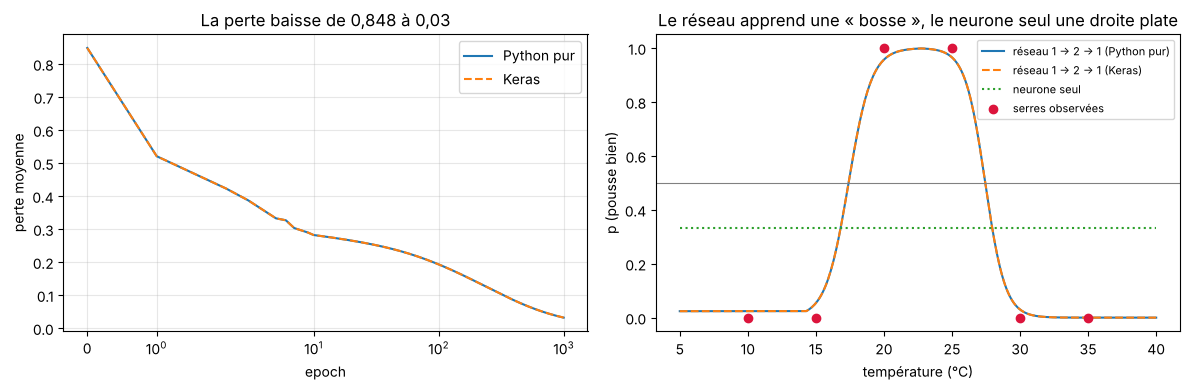

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot([hist[e][1] for e in range(1001)], label="Python pur")
ax[0].plot(range(1000), pertes_keras, "--", label="Keras")
ax[0].set_xscale("symlog"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("perte moyenne")
ax[0].set_title("La perte baisse de 0,848 à 0,03"); ax[0].legend(); ax[0].grid(alpha=0.3)

tt = np.linspace(5, 40, 351)
ax[1].plot(tt, [forward(P_final, t / 10)[-1] for t in tt], label="réseau 1 → 2 → 1 (Python pur)")
ax[1].plot(tt, modele.predict(tt.reshape(-1, 1) / 10, verbose=0).ravel(), "--", label="réseau 1 → 2 → 1 (Keras)")
ax[1].plot(tt, logit.predict_proba(tt.reshape(-1, 1) / 10)[:, 1], ":", label="neurone seul")
ax[1].scatter(T, Y, c="crimson", zorder=3, label="serres observées")
ax[1].axhline(0.5, color="grey", lw=0.8)
ax[1].set_xlabel("température (°C)"); ax[1].set_ylabel("p (pousse bien)")
ax[1].set_title("Le réseau apprend une « bosse », le neurone seul une droite plate"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Conclusion


**À retenir**
- Un neurone seul ne trace qu’**une** frontière. Une **couche cachée** permet de combiner plusieurs frontières : ici, « assez chaud » **et pas** « trop chaud ».
- Chaque neurone caché apprend un rôle lisible : un seuil de température et un vote (+ ou −) vers la sortie.
- Entraîner = répéter **forward → perte → rétropropagation → mise à jour** ; un neurone ReLU éteint ne reçoit pas de gradient.
- Batch = plusieurs exemples, gradient moyen ; epoch = toutes les données vues une fois ; itérations par epoch $= \lceil N/B \rceil$. Les poids ne repartent jamais de zéro.